# Detector de matrículas con YOLO11n

1. Modelo base a 1280
2. Entrenamiento del modelo final
3. Comparación en test
4. Comparación en el vídeo
5. Vídeo final

**Para ejecutarlo:** abre el cuaderno desde la carpeta `P4`, con el kernel del entorno `VC_P4`, y pulsa **Ejecutar todo**. Con la configuración por defecto usa los resultados ya guardados y solo genera el vídeo final, en unos 5 minutos. Para repetir un paso, activa su opción en la celda de configuración.

## Configuración

In [1]:
import csv
import random
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np
import torch
from IPython.display import Image, display
from ultralytics import YOLO

# Qué se ejecuta. Lo largo viene desactivado porque sus resultados ya están guardados.
ENTRENAR_BASE = False    # sección 1: modelo base a 1280 (unas horas sin Colab)
ENTRENAR = False         # sección 2: modelo final (alrededor de 1 hora)
EVALUAR_TEST = False     # sección 3: compara los modelos en test (1-2 minutos)
COMPARAR_VIDEO = False   # sección 4: compara los modelos en el vídeo (unos minutos)
GENERAR_VIDEO = True     # sección 5: genera el vídeo final (unos 5 minutos)
MOSTRAR_VENTANA = False  # True muestra el vídeo mientras se genera; pulsa q para parar
MAX_FOTOGRAMAS = None    # None = vídeo completo; un número sirve para una prueba rápida

AQUI = Path.cwd()
assert (AQUI / "yolo11n.pt").exists(), f"Abre el cuaderno desde la carpeta P4 (ahora: {AQUI})"
RAIZ = AQUI.parent
RUNS = AQUI / "runs"
DATASET_LIMPIO = RAIZ / "datos" / "dataset_limpio"
DATASET_REDUCIDO = RAIZ / "datos" / "dataset_lejanas"
VIDEO = RAIZ / "datos" / "videos" / "C0142.MP4"
VIDEO_SALIDA = AQUI / "resultado_matriculas" / "salida_C0142_lejanas.mp4"
DIR_COMPARACION = RUNS / "comparacion_lejanas"

MODELO_GENERAL = AQUI / "yolo11n.pt"
NOMBRE_BASE = "matriculas_yolo11n_1280"
NOMBRE_FINAL = "matriculas_yolo11n_lejanas"
PESOS = {
    "640": RUNS / "matriculas_yolo11n" / "weights" / "best.pt",
    "1280": RUNS / NOMBRE_BASE / "weights" / "best.pt",
    "final": RUNS / NOMBRE_FINAL / "weights" / "best.pt",
}
IMGSZ = 1920  # resolución completa del vídeo, para no reducir las matrículas lejanas
CONF = 0.25
VEHICULOS = [2, 3, 5, 7]  # coche, moto, autobús, camión
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

Dispositivo: 0


## 1. Modelo base a 1280

YOLO11n preentrenado en COCO y entrenado con `dataset_limpio` (151 imágenes de train), con `imgsz=1280` y más aumento de escala. Se entrenó en Colab. Da mejores resultados con matrículas de tamaño normal, pero no llega a las lejanas del vídeo: es solo el punto de partida del modelo final.

In [2]:
if ENTRENAR_BASE:
    # batch=4: a 1280 la memoria se dispara; si da CUDA out of memory, bájalo a 2
    YOLO(str(MODELO_GENERAL)).train(data=str(DATASET_LIMPIO / "data.yaml"), epochs=60, imgsz=1280, batch=4,
                                    scale=0.9, mosaic=1.0, device=DEVICE, workers=2, amp=False,
                                    project=str(RUNS), name=NOMBRE_BASE, exist_ok=True)
else:
    print("Se usa el modelo base ya entrenado:", PESOS["1280"])

Se usa el modelo base ya entrenado: D:\CarpetaDescargasC\Documentos\AaCurso27\VC\Practica4\VC_P4\P4\runs\matriculas_yolo11n_1280\weights\best.pt


## 2. Entrenamiento del modelo final

Se entrena con **todas las imágenes a la vez**: las 151 originales de `dataset_limpio`, con matrículas de tamaño normal, y 1200 lienzos con matrículas pequeñas (`dataset_lejanas`).

**Por qué hace falta el data augmentation:** en el dataset, la matrícula más pequeña mide 31 px de ancho a `imgsz=640`, y en el vídeo de test la de un coche lejano mide unos 17×4 px. El script `generar_dataset_reducido.py` crea esos ejemplos a partir de las mismas imágenes, reduciendo recortes de coches hasta matrículas de 12 a 120 px, con desenfoque y compresión para imitar el vídeo. Cada split usa solo sus imágenes y el vídeo de test no se usa para generar nada.

Parte de los pesos a 1280. Se entrena a `imgsz=960` sobre lienzos a la escala del vídeo; después se infiere a `imgsz=1920` sobre el fotograma completo, sin reducirlo, y la matrícula mantiene su tamaño.

In [3]:
datos_yaml = DATASET_REDUCIDO / "data.yaml"
assert datos_yaml.exists(), "Falta el dataset: ejecuta python P4/generar_dataset_reducido.py"

n_originales = len(list((DATASET_LIMPIO / "train" / "images").glob("*.jpg")))
n_reducidas = len(list((DATASET_REDUCIDO / "train" / "images").glob("*.jpg")))
print(f"Imágenes de entrenamiento: {n_originales} originales + {n_reducidas} con matrículas reducidas = {n_originales + n_reducidas}")

if ENTRENAR:
    YOLO(str(PESOS["1280"])).train(
        data=str(datos_yaml),  # incluye las imágenes originales y las reducidas
        epochs=60,
        patience=20,
        imgsz=960,
        batch=8,
        amp=False,       # con AMP la pérdida se iba a nan
        mosaic=0.0,      # el mosaico y el escalado encogerían placas que ya son muy pequeñas
        close_mosaic=0,
        scale=0.25,
        erasing=0.0,
        workers=2,
        device=DEVICE,
        project=str(RUNS),
        name=NOMBRE_FINAL,
        exist_ok=True,
        seed=42,
    )
else:
    print("Se usa el modelo final ya entrenado:", PESOS["final"])

Imágenes de entrenamiento: 151 originales + 1200 con matrículas reducidas = 1351
Se usa el modelo final ya entrenado: D:\CarpetaDescargasC\Documentos\AaCurso27\VC\Practica4\VC_P4\P4\runs\matriculas_yolo11n_lejanas\weights\best.pt


Épocas: 60 | mejor época: 59 | precisión 0.946 | recall 0.876 | mAP50 0.911 | mAP50-95 0.578


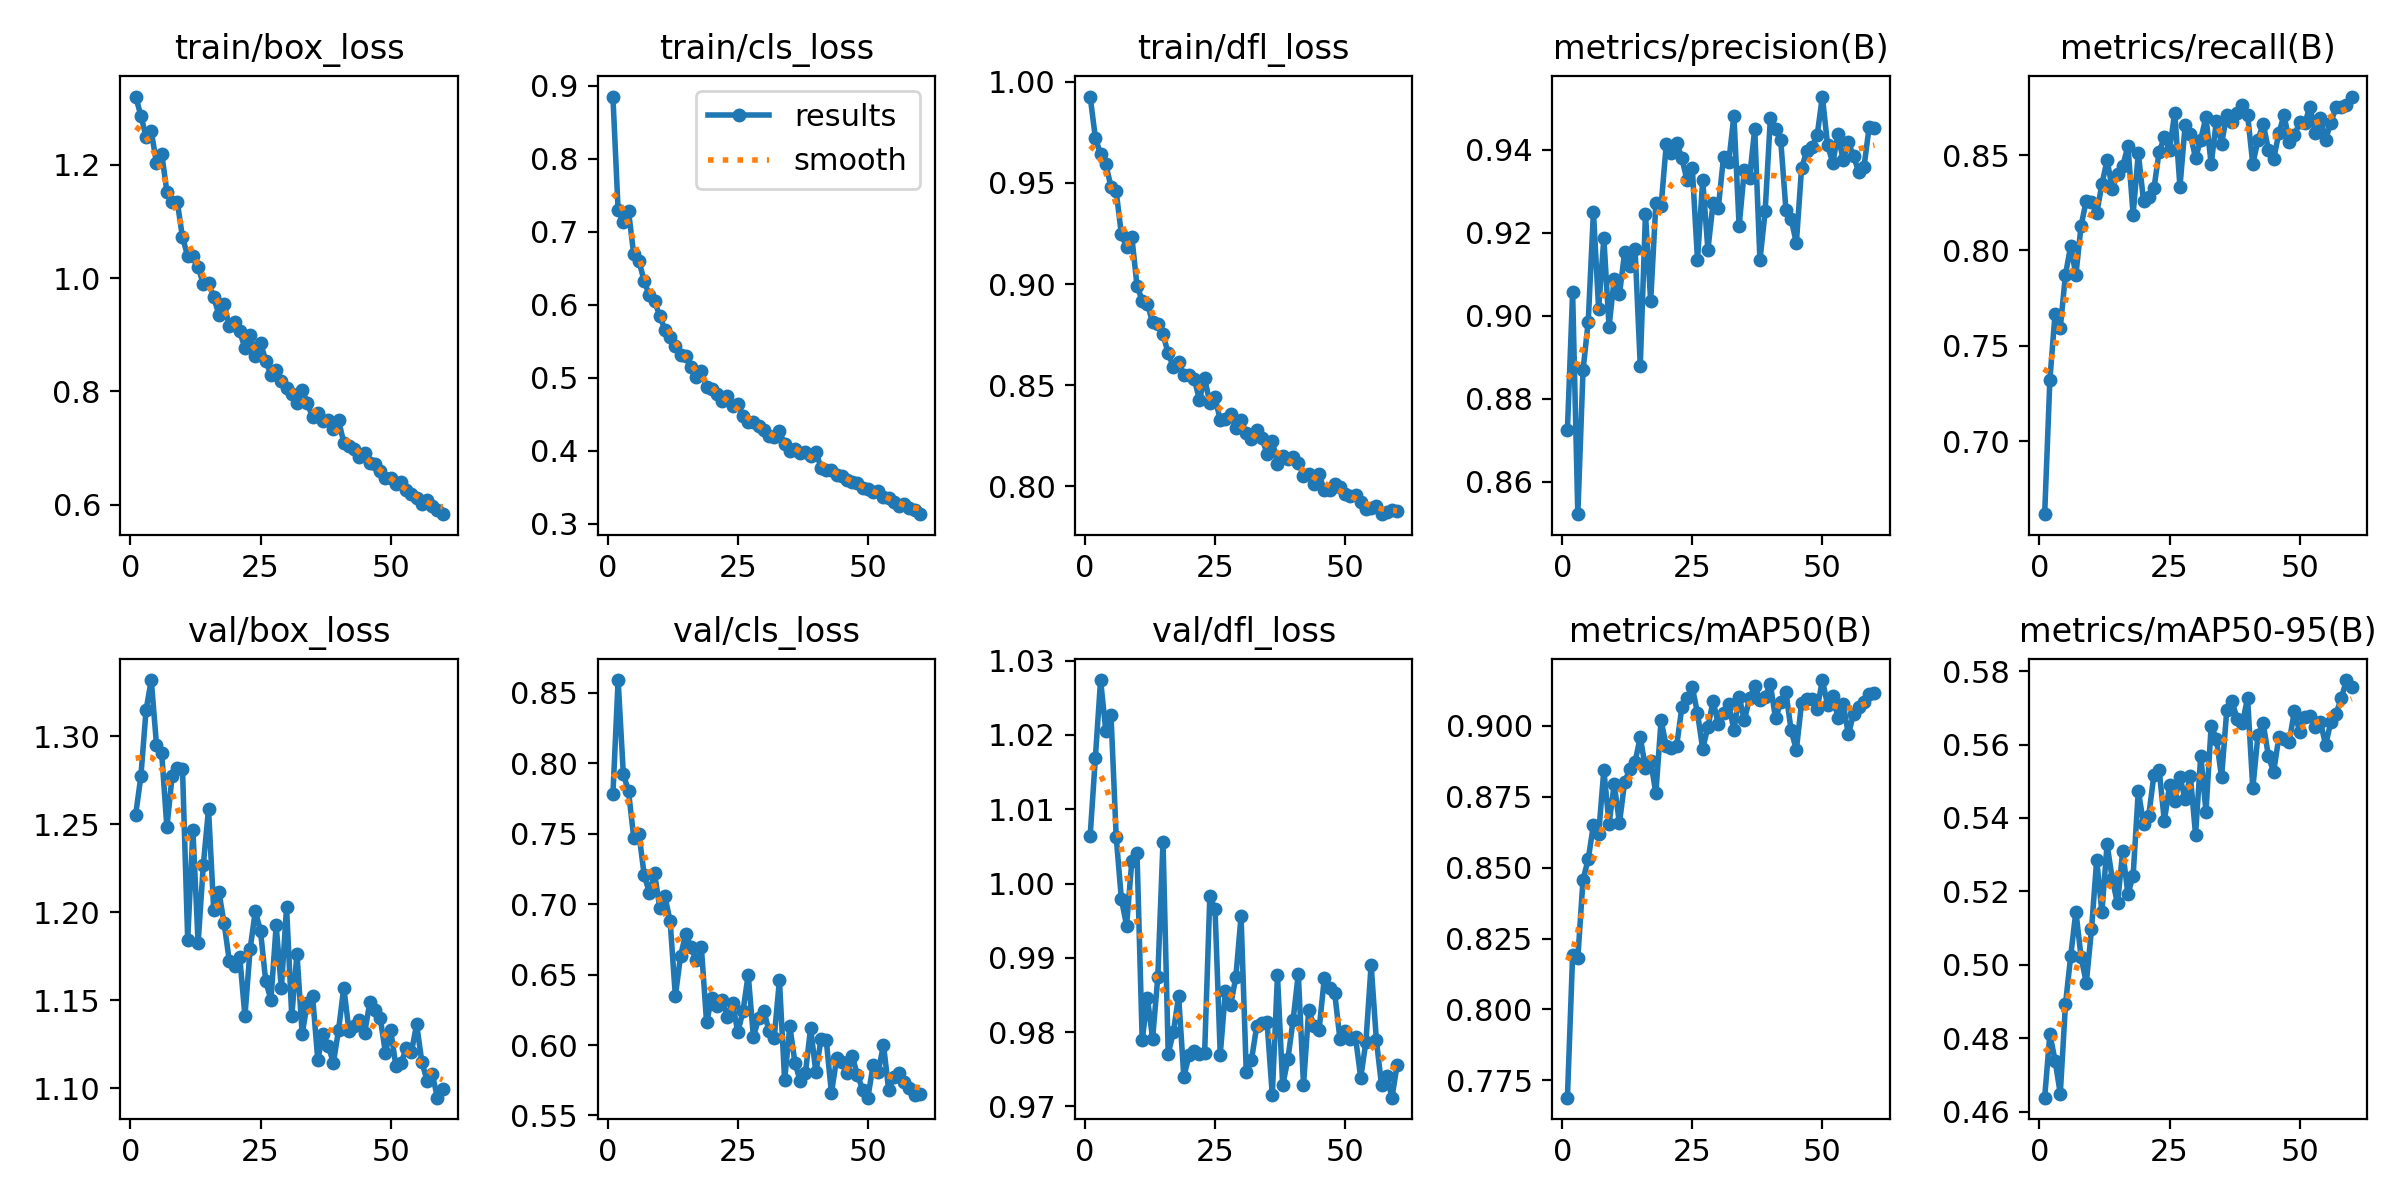

In [4]:
with open(RUNS / NOMBRE_FINAL / "results.csv", encoding="utf-8") as f:
    filas = [{k.strip(): v for k, v in fila.items()} for fila in csv.DictReader(f)]
mejor = max(filas, key=lambda x: float(x["metrics/mAP50-95(B)"]))
print(f"Épocas: {len(filas)} | mejor época: {mejor['epoch']} | precisión {float(mejor['metrics/precision(B)']):.3f} | "
      f"recall {float(mejor['metrics/recall(B)']):.3f} | mAP50 {float(mejor['metrics/mAP50(B)']):.3f} | "
      f"mAP50-95 {float(mejor['metrics/mAP50-95(B)']):.3f}")
display(Image(filename=str(RUNS / NOMBRE_FINAL / "results.png"), width=900))

## 3. Comparación en test

- **Real:** las 32 matrículas de test de `dataset_limpio`. Comprueba que el modelo no empeora con matrículas normales.
- **Reducidas:** las matrículas de test del dataset generado. Es un test sintético y puede dar una imagen optimista.

In [5]:
def mostrar_csv(ruta):
    with open(ruta, encoding="utf-8") as f:
        filas = list(csv.reader(f))
    anchos = [max(len(fila[i]) for fila in filas) for i in range(len(filas[0]))]
    for fila in filas:
        print("  ".join(v.rjust(a) for v, a in zip(fila, anchos)))


RUTA_TEST = DIR_COMPARACION / "test.csv"
if EVALUAR_TEST:
    DIR_COMPARACION.mkdir(parents=True, exist_ok=True)
    casos = [("640", "real", DATASET_LIMPIO, 640), ("640", "reducidas", DATASET_REDUCIDO, 960),
             ("1280", "real", DATASET_LIMPIO, 1280), ("1280", "reducidas", DATASET_REDUCIDO, 960),
             ("final", "real", DATASET_LIMPIO, 960), ("final", "reducidas", DATASET_REDUCIDO, 960)]
    with open(RUTA_TEST, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["modelo", "test", "imgsz", "precision", "recall", "mAP50", "mAP50-95"])
        for nombre, conjunto, datos, tam in casos:
            m = YOLO(str(PESOS[nombre])).val(data=str(datos / "data.yaml"), split="test", imgsz=tam, batch=4,
                                             plots=False, verbose=False, project=str(DIR_COMPARACION / "val"),
                                             name=f"{nombre}_{conjunto}", exist_ok=True)
            w.writerow([nombre, conjunto, tam] + [f"{v:.3f}" for v in (m.box.mp, m.box.mr, m.box.map50, m.box.map)])

mostrar_csv(RUTA_TEST)

modelo       test  imgsz  precision  recall  mAP50  mAP50-95
   640       real    640      0.935   0.969  0.960     0.776
   640  reducidas    960      0.770   0.314  0.367     0.208
  1280       real   1280      0.958   0.969  0.982     0.782
  1280  reducidas    960      0.874   0.353  0.413     0.266
 final       real    960      0.944   0.938  0.960     0.771
 final  reducidas    960      0.937   0.849  0.904     0.580


## 4. Comparación en el vídeo

El vídeo no tiene etiquetas, así que esto es una aproximación. Una detección es "plausible" si cae en la parte baja de un vehículo y tiene forma de matrícula: **no equivale a precisión** y no dice cuántas matrículas se pierden. Las columnas `p15_20` y similares cuentan las detecciones plausibles por ancho en píxeles.

In [6]:
CONFIGS = [("640", 1280), ("640", 1920), ("1280", 1280), ("1280", 1920), ("final", 1280), ("final", 1920)]
UMBRALES = [0.15, 0.25, 0.40]
TRAMOS = [(0, 15), (15, 20), (20, 25), (25, 30), (30, 45), (45, 9999)]
PASO = 10  # se evalúa 1 de cada 10 fotogramas


def dentro_de_vehiculo(caja, vehiculos, ratio_min=1.2):
    """Acepta la caja si tiene forma de matrícula y está en la parte baja de un vehículo."""
    x1, y1, x2, y2 = caja
    ancho, alto = x2 - x1, y2 - y1
    if alto <= 0 or not ratio_min <= ancho / alto <= 6.5:
        return False
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    for vx1, vy1, vx2, vy2 in vehiculos:
        v_ancho, v_alto = vx2 - vx1, vy2 - vy1
        if (vx1 <= cx <= vx2 and vy1 + 0.35 * v_alto <= cy <= vy2 + 0.05 * v_alto
                and ancho <= 0.65 * v_ancho):
            return True
    return False


def hoja(filas, cap, ruta, titulo, n=30):
    """Hoja de contacto con un recorte ampliado de cada detección."""
    random.Random(1).shuffle(filas)
    tiles = []
    for f in filas[:n]:
        cap.set(cv2.CAP_PROP_POS_FRAMES, f["frame"])
        ok, img = cap.read()
        if not ok:
            continue
        x1, y1, x2, y2 = f["caja"]
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        lado = max(70, (x2 - x1) * 4)
        a, b = int(max(cx - lado / 2, 0)), int(max(cy - lado / 2, 0))
        rec = img[b:int(b + lado), a:int(a + lado)]
        e = 220 / max(rec.shape[:2])
        t = cv2.resize(rec, None, fx=e, fy=e, interpolation=cv2.INTER_CUBIC)
        t = cv2.copyMakeBorder(t, 0, 220 - t.shape[0], 0, 220 - t.shape[1], cv2.BORDER_CONSTANT)
        cv2.rectangle(t, (int((x1 - a) * e), int((y1 - b) * e)), (int((x2 - a) * e), int((y2 - b) * e)), (0, 255, 0), 1)
        cv2.putText(t, f"{x2 - x1:.0f}x{y2 - y1:.0f} c{f['conf']:.2f}", (3, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
        tiles.append(t)
    if not tiles:
        return
    while len(tiles) % 6:
        tiles.append(np.zeros_like(tiles[0]))
    cv2.imwrite(str(ruta), np.vstack([np.hstack(tiles[i:i + 6]) for i in range(0, len(tiles), 6)]))
    print("  hoja:", ruta.name, titulo)


def comparar_video():
    DIR_COMPARACION.mkdir(parents=True, exist_ok=True)
    modelos = {k: YOLO(str(v)) for k, v in PESOS.items()}
    gen = YOLO(str(MODELO_GENERAL))
    cap = cv2.VideoCapture(str(VIDEO))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    dets, tiempos, n = defaultdict(list), defaultdict(float), 0
    for f in range(0, total, PASO):
        cap.set(cv2.CAP_PROP_POS_FRAMES, f)
        ok, img = cap.read()
        if not ok:
            continue
        n += 1
        veh = gen(img, imgsz=1920, conf=0.15, classes=VEHICULOS, verbose=False)[0].boxes.xyxy.cpu().numpy()
        for nombre, sz in CONFIGS:
            r = modelos[nombre](img, imgsz=sz, conf=0.10, verbose=False)[0]
            tiempos[(nombre, sz)] += r.speed["inference"]
            for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                caja = tuple(float(v) for v in b)
                dets[(nombre, sz)].append({"frame": f, "caja": caja, "conf": float(c),
                                           "ok": dentro_de_vehiculo(caja, veh, ratio_min=1.5)})
    print(f"Fotogramas evaluados: {n}")

    with open(DIR_COMPARACION / "resumen.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        w.writerow(["modelo", "imgsz", "conf", "ms", "total", "plausibles", "no_plausibles"] + [f"p{a}_{b}" for a, b in TRAMOS])
        for (nombre, sz), lista in dets.items():
            for u in UMBRALES:
                sel = [d for d in lista if d["conf"] >= u]
                pl = [d for d in sel if d["ok"]]
                tr = [sum(a <= d["caja"][2] - d["caja"][0] < b for d in pl) for a, b in TRAMOS]
                w.writerow([nombre, sz, u, round(tiempos[(nombre, sz)] / n, 1), len(sel), len(pl), len(sel) - len(pl)] + tr)

    lista = dets[("final", 1920)]
    for a, b in TRAMOS[:-1]:
        sel = [d for d in lista if d["ok"] and d["conf"] >= CONF and a <= d["caja"][2] - d["caja"][0] < b]
        hoja(sel, cap, DIR_COMPARACION / f"lejanas_plausibles_{a}_{b}.jpg", f"({len(sel)} detecciones)")
    sel = [d for d in lista if not d["ok"] and d["conf"] >= CONF]
    hoja(sel, cap, DIR_COMPARACION / "lejanas_no_plausibles.jpg", f"({len(sel)} detecciones)")
    cap.release()


if COMPARAR_VIDEO:
    comparar_video()

mostrar_csv(DIR_COMPARACION / "resumen.csv")

modelo  imgsz  conf    ms  total  plausibles  no_plausibles  p0_15  p15_20  p20_25  p25_30  p30_45  p45_9999
   640   1920  0.15  24.6     96          91              5      0       0       0       0      21        70
   640   1920  0.25  24.6     81          77              4      0       0       0       0      16        61
   640   1920   0.4  24.6     68          65              3      0       0       0       0      13        52
  1280   1920  0.15  24.7    133         126              7      0       0       3       7      46        70
  1280   1920  0.25  24.7    116         112              4      0       0       2       6      38        66
  1280   1920   0.4  24.7     97          96              1      0       0       0       4      30        62
 final   1280  0.15  15.8    254         252              2      1      34      50      31      55        81
 final   1280  0.25  15.8    234         233              1      0      25      44      30      53        81
 final   1280   0.4

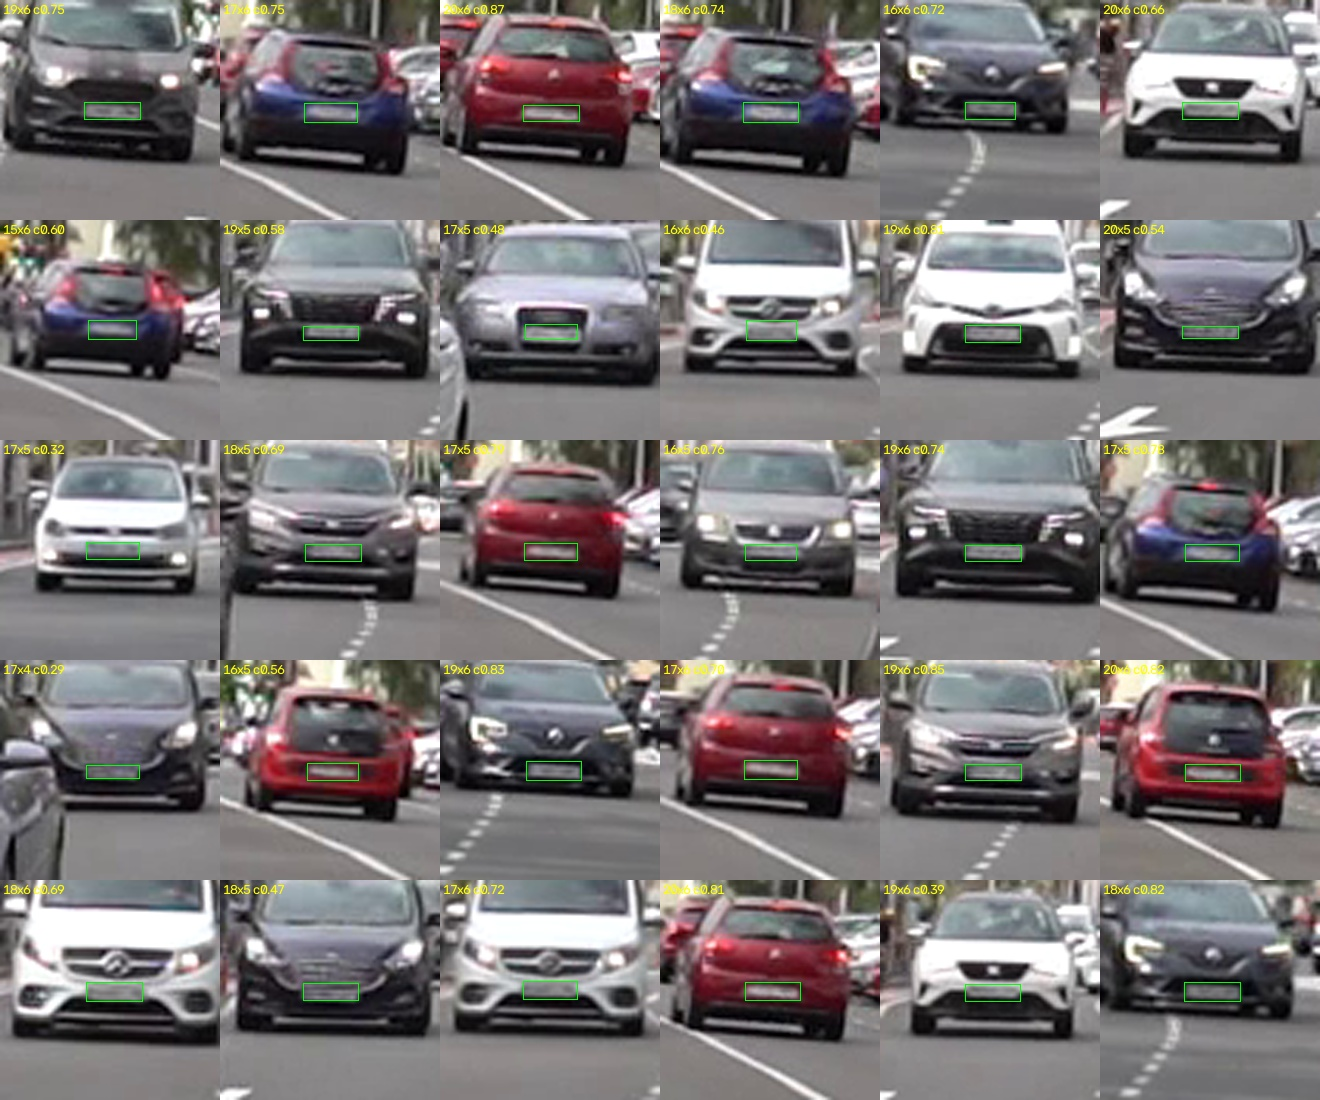

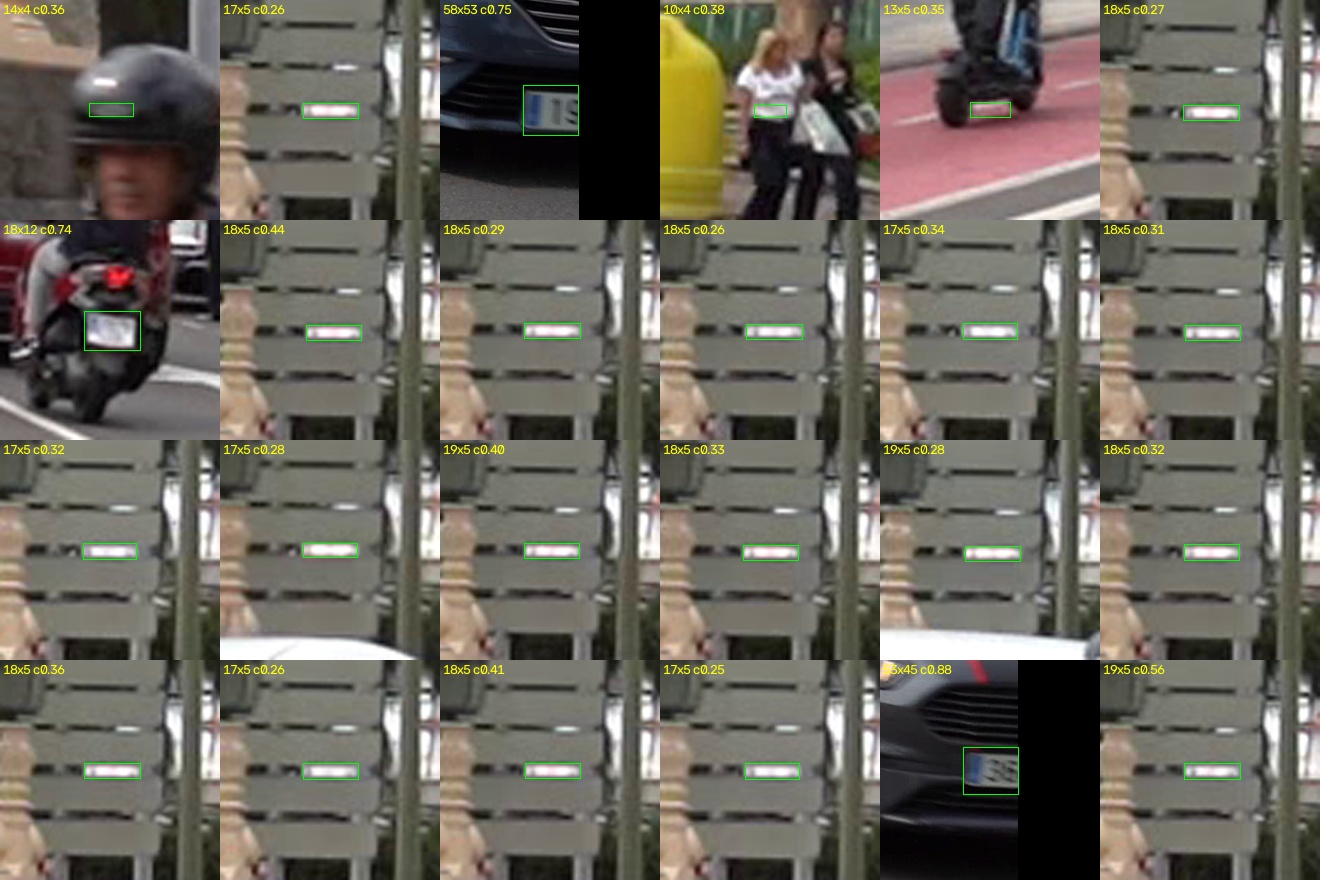

In [7]:
# Ejemplos de placas de 15-20 px detectadas por el modelo final
display(Image(filename=str(DIR_COMPARACION / "lejanas_plausibles_15_20.jpg"), width=900))
# Detecciones descartadas: casi todas son el mismo hueco de un cartel fijo
display(Image(filename=str(DIR_COMPARACION / "lejanas_no_plausibles.jpg"), width=900))

## 5. Vídeo final

Detecta los vehículos y las matrículas a resolución completa, y solo dibuja las matrículas que caen dentro de un vehículo. Así se descartan falsos positivos del fondo, como el hueco del cartel fijo. Si pulsas `q`, el vídeo se corta en ese punto.

In [8]:
def generar_video():
    modelo = YOLO(str(PESOS["final"]))
    detector_vehiculos = YOLO(str(MODELO_GENERAL))
    VIDEO_SALIDA.parent.mkdir(parents=True, exist_ok=True)

    vid = cv2.VideoCapture(str(VIDEO))
    fps = vid.get(cv2.CAP_PROP_FPS) or 25
    w = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
    out = cv2.VideoWriter(str(VIDEO_SALIDA), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    fotogramas = placas_dibujadas = 0
    while MAX_FOTOGRAMAS is None or fotogramas < MAX_FOTOGRAMAS:
        ret, img = vid.read()
        if not ret:
            break

        vehiculos = detector_vehiculos(img, imgsz=IMGSZ, conf=0.15, classes=VEHICULOS,
                                       verbose=False)[0].boxes.xyxy.cpu().numpy()
        placas = modelo(img, imgsz=IMGSZ, conf=CONF, verbose=False)[0].boxes

        for caja, conf in zip(placas.xyxy.cpu().numpy(), placas.conf.cpu().numpy()):
            if not dentro_de_vehiculo(caja, vehiculos):
                continue
            x1, y1, x2, y2 = map(int, caja)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 255), 2)
            cv2.putText(img, f"Matricula {conf:.2f}", (x1, max(y1 - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 255), 2)
            placas_dibujadas += 1

        out.write(img)
        fotogramas += 1
        if MOSTRAR_VENTANA:
            cv2.imshow("Matriculas", img)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    vid.release()
    out.release()
    cv2.destroyAllWindows()
    print(f"{fotogramas} fotogramas y {placas_dibujadas} matrículas dibujadas. Vídeo guardado en {VIDEO_SALIDA}")


if GENERAR_VIDEO:
    generar_video()
else:
    print("Vídeo ya generado:", VIDEO_SALIDA)

2832 fotogramas y 2714 matrículas dibujadas. Vídeo guardado en D:\CarpetaDescargasC\Documentos\AaCurso27\VC\Practica4\VC_P4\P4\resultado_matriculas\salida_C0142_lejanas.mp4
